# 04 - Detection metrics: TP/FP/FN, precision, recall, AP, mAP

**Question:** how do we turn a list of predicted boxes into numbers that say how good the detector is?

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG = os.path.abspath("../figures"); RES = os.path.abspath("../results")
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)
VOC = os.path.abspath("../data/VOCdevkit/VOC2007")
from src.metrics import precision_recall, pr_curve, average_precision, f1_score
from src.evaluation import Evaluator, IOU_RANGE

## 1. Concept

A prediction is **correct (TP)** if it has the right class and IoU with a not-yet-matched ground-truth box >= the IoU threshold (0.5 for mAP@50). Otherwise it is a **false positive (FP)**. A ground-truth object nobody found is a **false negative (FN)**.

```
precision = TP / (TP + FP)     "of what I predicted, how much was right?"
recall    = TP / (TP + FN)     "of what existed, how much did I find?"
```

Matching rules used in this repo (Pascal VOC):
1. visit predictions from highest to lowest confidence;
2. a prediction is compared with all ground-truth boxes of its class in the same image and takes the best IoU;
3. second prediction on an already matched object = **duplicate = FP**;
4. objects marked *difficult* are neither rewarded nor penalised.

Changing the confidence threshold slides along a trade-off: more predictions kept -> usually more recall, less precision.

## 2. The cat example from the guide, computed

3 real cats, the detector finds 2, and also fires on a patch of grass: TP = 2, FP = 1, FN = 1.

In [2]:
p, r = precision_recall(tp=2, fp=1, fn=1)
print(f"precision = 2/3 = {p:.3f}, recall = 2/3 = {r:.3f}")
# the same situation as real boxes, through the evaluator
gt = {"img": dict(boxes=np.array([[0,0,10,10],[20,0,30,10],[40,0,50,10.]]), labels=np.zeros(3, int), difficult=np.zeros(3, bool))}
dt = {"img": dict(boxes=np.array([[0,0,10,10],[20,0,30,10],[60,0,70,10.]]), scores=np.array([.98,.90,.70]), labels=np.zeros(3, int))}
m = Evaluator(gt, dt, num_classes=1).metrics(0.5)
print({k: m[k] for k in ("tp", "fp", "fn", "precision", "recall")})
assert (m["tp"], m["fp"], m["fn"]) == (2, 1, 1)

precision = 2/3 = 0.667, recall = 2/3 = 0.667
{'tp': 2, 'fp': 1, 'fn': 1, 'precision': 0.6666666666666666, 'recall': 0.6666666666666666}


## 3. Confidence threshold, then the precision-recall curve

Add a 4th prediction (the third cat, found with low confidence 0.35) and sweep the threshold.

In [3]:
dt = {"img": dict(boxes=np.array([[0,0,10,10],[20,0,30,10],[60,0,70,10.],[40,0,50,10.]]), scores=np.array([.98,.90,.70,.35]), labels=np.zeros(4, int))}
ev = Evaluator(gt, dt, num_classes=1)
rows = []
for t in (0.0, 0.3, 0.5, 0.8, 0.95):
    m = ev.metrics(0.5, conf_thr=t); rows.append(dict(conf_threshold=t, kept=m["n_det"], TP=m["tp"], FP=m["fp"], FN=m["fn"], precision=round(m["precision"], 3), recall=round(m["recall"], 3)))
display(pd.DataFrame(rows))
rec, prec, sc = ev.pr_curve_all(0.5)
print("sorted detections (score):", sc, "\nrecall   :", rec.round(3), "\nprecision:", prec.round(3))

,conf_threshold,kept,TP,FP,FN,precision,recall
0,0.00,4,3,1,0,0.750,1.000
1,0.30,4,3,1,0,0.750,1.000
2,0.50,3,2,1,1,0.667,0.667
3,0.80,2,2,0,1,1.000,0.667
4,0.95,1,1,0,2,1.000,0.333


sorted detections (score): [0.98 0.9  0.7  0.35] 
recall   : [0.333 0.667 0.667 1.   ] 
precision: [1.    1.    0.667 0.75 ]


## 4. Average Precision by hand

Detections sorted by confidence: TP, TP, FP, TP -> precision 1, 1, 0.667, 0.75 at recall 1/3, 2/3, 2/3, 1.

AP = area under the precision-recall curve after making precision monotone (at each recall use the best precision at that recall or higher). Here that is `1/3*1 + 1/3*1 + 1/3*0.75 = 0.917`.

AP (all points) = 0.9167   by hand = 0.9167
AP (11 point, VOC2007 style) = 0.9091


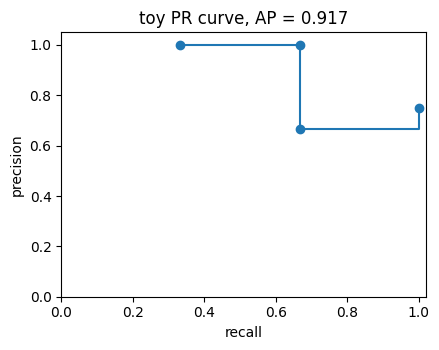

In [4]:
ap = average_precision(rec, prec); ap11 = average_precision(rec, prec, "11_point")
print(f"AP (all points) = {ap:.4f}   by hand = {1/3 + 1/3 + 0.75/3:.4f}")
print(f"AP (11 point, VOC2007 style) = {ap11:.4f}")
assert abs(ap - (2/3 + 0.75/3)) < 1e-9
fig, ax = plt.subplots(figsize=(4.5, 3.6)); ax.step(rec, prec, where="post", marker="o"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title(f"toy PR curve, AP = {ap:.3f}"); plt.tight_layout(); plt.show()

## 5. mAP = mean of per-class AP; matching rules on a toy case

Two classes (AP 0.9 and 0.7 -> mAP 0.8 is just the average). The next cell shows the duplicate and difficult-object rules.

In [5]:
print("mAP of APs [0.9, 0.7] =", np.mean([0.9, 0.7]))
gts = {"a": dict(boxes=np.array([[0,0,10,10],[50,50,60,60],[80,80,90,90.]]), labels=np.zeros(3, int), difficult=np.array([False, False, True]))}
dts = {"a": dict(boxes=np.array([[0,0,10,10],[1,1,10,10],[50,50,60,60],[80,80,90,90],[200,200,210,210.]]),
                 scores=np.array([.9, .8, .7, .6, .5]), labels=np.zeros(5, int))}
m = Evaluator(gts, dts, 1).metrics(0.5)
print("5 predictions -> TP", m["tp"], "FP", m["fp"], "FN", m["fn"], "| n_gt counted", m["n_gt"])
print("  TP: 0.9 and 0.7;  FP: 0.8 (duplicate of the first object) and 0.5 (background);  0.6 hits a *difficult* object -> ignored")

mAP of APs [0.9, 0.7] = 0.8
5 predictions -> TP 2 FP 2 FN 0 | n_gt counted 2
  TP: 0.9 and 0.7;  FP: 0.8 (duplicate of the first object) and 0.5 (background);  0.6 hits a *difficult* object -> ignored


## 6. IoU threshold: mAP@50 vs mAP@50:95

The IoU used for matching decides what 'correct' means. `mAP@50:95` averages AP over IoU thresholds 0.50, 0.55, ..., 0.95, so it rewards tight boxes. Real detector, real data (YOLOv8n, 640 px, 1,000 VOC2007-test images, confidence >= 0.01 so that the curve is complete):

,0,1,2,3,4,5,6,7,8,9
IoU threshold,0.5000,0.5500,0.60,0.6500,0.7000,0.7500,0.8000,0.85,0.9000,0.9500
mAP,0.8271,0.8143,0.79,0.7551,0.7191,0.6616,0.6004,0.47,0.3079,0.0953


mAP@50 = 0.8271   mAP@50:95 = 0.6041


,class,objects,AP@50,AP@75
0,aeroplane,66,0.864,0.661
1,bicycle,59,0.910,0.752
2,bird,101,0.876,0.609
3,boat,50,0.761,0.441
4,bottle,131,0.864,0.682
5,bus,44,0.920,0.828
6,car,259,0.899,0.705
7,cat,70,0.802,0.763
8,chair,157,0.622,0.411
9,cow,62,0.957,0.836


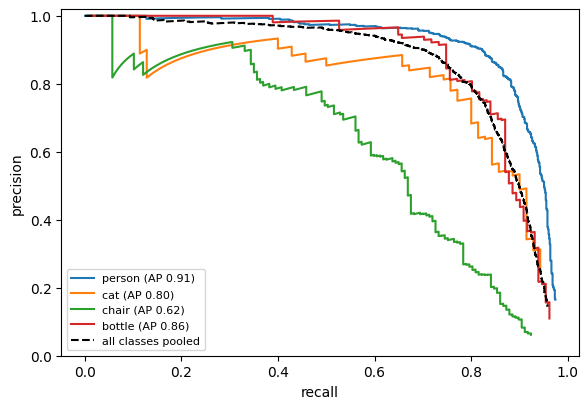

In [6]:
from src.experiments import load_gts, load_candidates, detections
from src.dataset import VOC_CLASSES
ids, gts = load_gts(); cands = load_candidates("clean_640")
ev = Evaluator(gts, detections(cands, 0.01, 0.5))
tab = pd.DataFrame({"IoU threshold": IOU_RANGE, "mAP": [ev.metrics(t)["map"] for t in IOU_RANGE]})
display(tab.round(4).T)
map50, map5095 = tab.mAP.iloc[0], tab.mAP.mean()
print(f"mAP@50 = {map50:.4f}   mAP@50:95 = {map5095:.4f}")
m50 = ev.metrics(0.5)
pc = pd.DataFrame({"class": VOC_CLASSES, "objects": m50["n_gt_c"], "AP@50": m50["ap"], "AP@75": ev.metrics(0.75)["ap"]})
pc.to_csv(f"{RES}/per_class_ap_clean640.csv", index=False); display(pc.round(3))
fig, ax = plt.subplots(figsize=(6, 4.2))
for cl in (14, 7, 8, 4): r_, p_, _ = ev.pr_curve_all(0.5, cl); ax.plot(r_, p_, label=f"{VOC_CLASSES[cl]} (AP {m50['ap'][cl]:.2f})")
r_, p_, _ = ev.pr_curve_all(0.5); ax.plot(r_, p_, "k--", label="all classes pooled")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{FIG}/precision_recall_curve.png", dpi=110); plt.show()

## 7. Cross-check against an independent implementation

The evaluator was compared with `pycocotools` (COCO evaluation uses a 101-point AP and slightly different matching, so tiny differences are expected). Produced by `scripts/cross_check.py`:

In [7]:
import json
p = f"{RES}/cross_check.json"
if os.path.exists(p):
    cc = json.load(open(p)); print(json.dumps(cc.get("pycocotools", cc), indent=1))
else:
    print("run `python scripts/cross_check.py data/VOCdevkit/VOC2007` to produce results/cross_check.json")

{
 "coco_map50": 0.8270109232544715,
 "coco_map50_95": 0.605756505741902,
 "ours_map50": 0.8270951523633256,
 "ours_map50_95": 0.6040885788918735
}


## 8. Observation

* Precision and recall answer different questions and move in opposite directions as the threshold changes (section 3).
* AP summarises the whole curve, so it does not depend on one chosen threshold; but a high confidence threshold removes the tail of the curve and lowers AP (shown with real data in notebook 06).
* `mAP@50` is clearly higher than `mAP@50:95` for this detector (section 6): finding an object is easier than boxing it tightly.
* Classes differ a lot (per-class table): mAP hides which classes are weak.